<a href="https://colab.research.google.com/github/BrownParticleAstro/dmtools_notebooks/blob/main/DMToolsPyPiExample_20261106_V0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DMTOOLS External API Guidance - 6 November 2026

Likely running from Colab

In [ ]:
from IPython.display import display
import json
import os

In [8]:
## Best Practice to keep secrets away from Notebook cells
def load_secrets(env_file_path=".env"):
    """
    Loads secrets from a .env file and retrieves 'EMAIL' and 'API_KEY'.

    Args:
        env_file_path (str): Path to the .env file. Defaults to '.env'.

    Returns:
        dict: A dictionary with 'email' and 'api_key' keys.

    Raises:
        FileNotFoundError: If the .env file does not exist.
        KeyError: If either EMAIL or API_KEY is missing.
    """
    if not os.path.exists(env_file_path):
        raise FileNotFoundError(f"{env_file_path} not found.")

    # Load environment variables from the file
    with open(env_file_path) as f:
        for line in f:
            line = line.strip()
            if line and not line.startswith('#'):
                key_value = line.split('=', 1)
                if len(key_value) == 2:
                    key, value = key_value
                    os.environ[key.strip()] = value.strip()

    email = os.getenv('EMAIL')
    api_key = os.getenv('API_KEY')

    if not email or not api_key:
        missing = []
        if not email:
            missing.append('EMAIL')
        if not api_key:
            missing.append('API_KEY')
        raise KeyError(f"Missing required secrets: {', '.join(missing)}")

    return {"email": email, "api_key": api_key}

# Install new dmtools_libraries

In [1]:
from google.colab import userdata
import subprocess
import base64
import os
import shutil
import sys

target_dir = "/content/dmtools_libraries"

# Avoid Git error 128 by removing the directory if it already exists
if os.path.exists(target_dir):
    print(f"Removing existing directory {target_dir} to prepare for clean clone...")
    shutil.rmtree(target_dir)

token = userdata.get("github_token")
auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()

try:
    subprocess.run([
        "git",
        "-c", f"http.extraHeader=Authorization: Basic {auth}",
        "clone",
        "--branch", "main",
        "--single-branch",
        "https://github.com/BrownParticleAstro/dmtools_libraries.git",
        target_dir
    ], check=True)
    print("Cloned successfully.")
except subprocess.CalledProcessError as e:
    print(f"Git clone failed with exit status {e.returncode}. Please check if your 'github_token' secret in Colab is valid and has access to the repository.")
    raise e

if target_dir not in sys.path:
    sys.path.insert(0, target_dir)

Cloned successfully.


In [2]:
# Removed Google Drive mount because it is unnecessary and causing a credential propagation error.
!pip install -e /content/dmtools_libraries

Obtaining file:///content/dmtools_libraries
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for dmtools_libraries (pyproject.toml) ... done
  Created wheel for dmtools_libraries: filename=dmtools_libraries-0.1.0-0.editable-py3-none-any.whl size=2364 sha256=59bbb6cf42eb25ce89c1072de598596fb0ea3f4f8d7517de796bdfc1b8d0101d
  Stored in directory: /tmp/pip-ephem-wheel-cache-2ox9zrul/wheels/4c/fa/67/5443974b53da1e50e04acef7cee22dc705c4133b27269d51a7
Successfully built dmtools_libraries


# Load Libraries

In [3]:
import sys
import importlib

# Ensure the source directory is in the path
src_path = "/content/dmtools_libraries/src"
if src_path not in sys.path:
    sys.path.insert(0, src_path)

# Force reload the module to clear any cached import failures
import dmtools_libraries
importlib.reload(dmtools_libraries)

from dmtools_libraries.helpers import convert_mass_units, get_x_label
from dmtools_libraries.trace import get_style_mpl
from dmtools_libraries.render_core import render_plot_core, render_legend_core
from dmtools_libraries.client import APIClient

print("Library location:", dmtools_libraries.__file__)
print(convert_mass_units(1.0, "GeV", "MeV"))
print(get_x_label("GeV"))
print(get_style_mpl("red", "line"))

Library location: /content/dmtools_libraries/src/dmtools_libraries/__init__.py
1000.0
$\mathrm{DM\ Mass}\ [\mathrm{GeV}/c^{2}]$
{'color': 'red', 'alpha': 1, 'linestyle': '-', 'linewidth': 1, 'marker': None, 'markersize': 0, 'fill': False, 'style': 'line'}


Colab render test


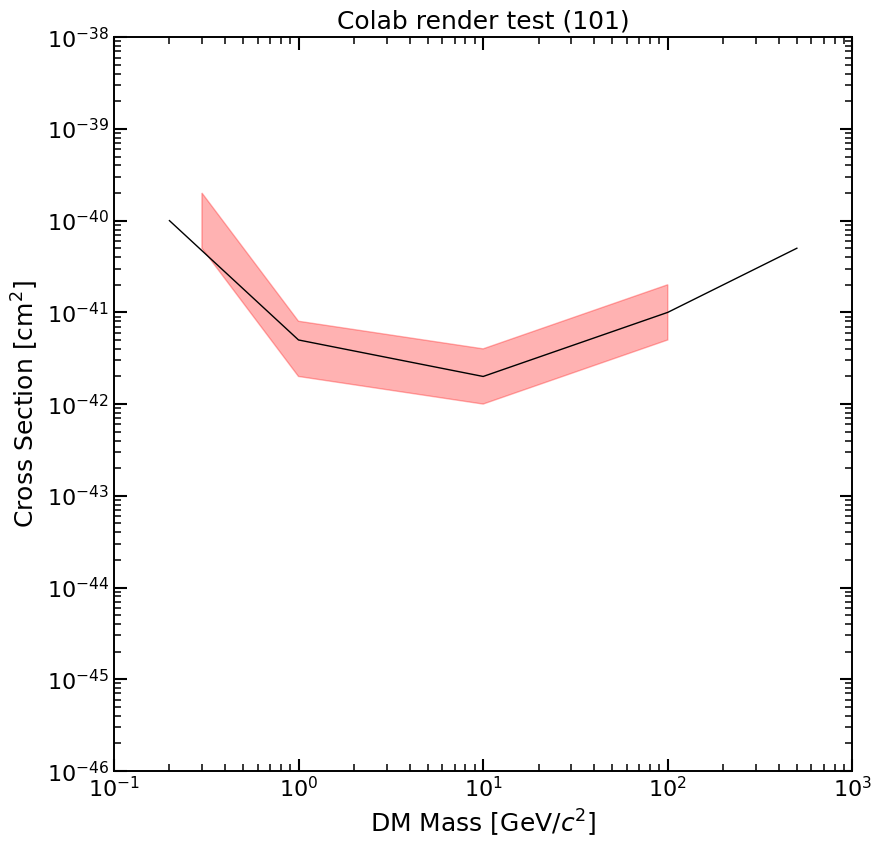

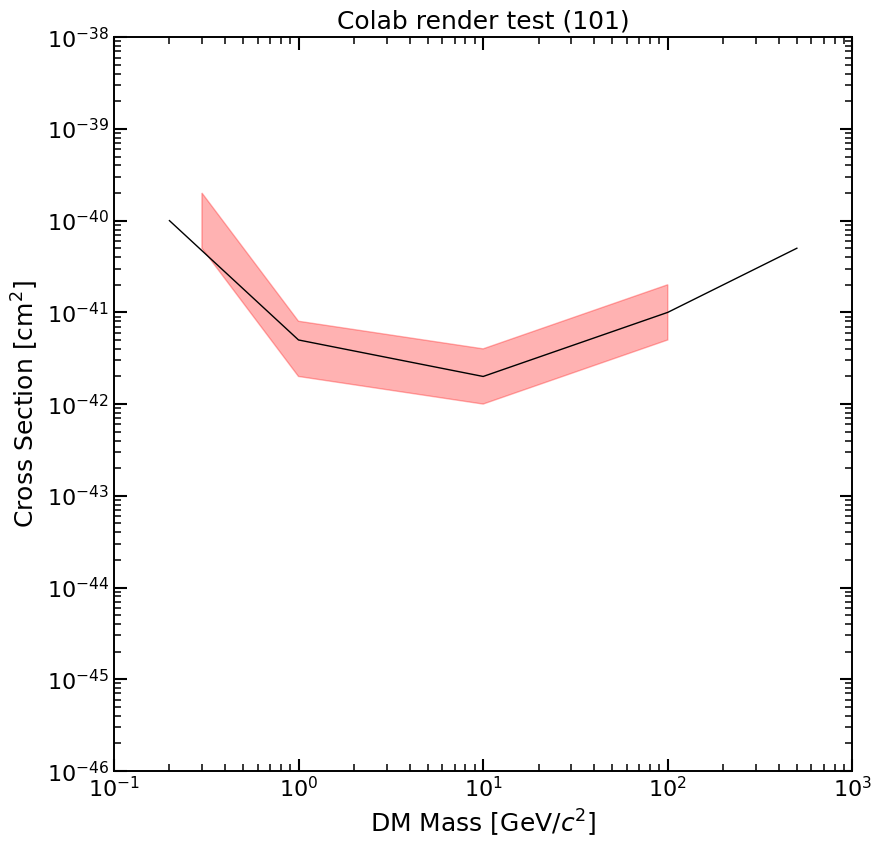

In [4]:
plot_data = {
    "plot_node": {
        "record": {"id": 101}
    }
}

plot_properties = {
    "name": "Colab render test",
    "plotType": "Cross Section vs WIMP Mass",
    "xUnits": "GeV/c^2",
    "xMin": 0.1,
    "xMax": 1000,
    "yMin": -46,  # y-axis bounds are powers of 10
    "yMax": -38,
}

display_data_list = [
    {
        "record": {"id": 1},
        "properties": {"color": "blue", "style": "line"},
        "data": [{
            "record": {"id": 11},
            "properties": {
                "label_short": "Example limit",
                "xUnits": "GeV/c^2",
                "xRescale": 1,
                "yRescale": 1,
                "values": [[
                    [0.2, 1e-40],
                    [1,   5e-42],
                    [10,  2e-42],
                    [100, 1e-41],
                    [500, 5e-41],
                ]],
            },
        }],
    },
    {
        "record": {"id": 2},
        "properties": {"color": "red", "style": "fill"},
        "data": [{
            "record": {"id": 22},
            "properties": {
                "label_short": "Example region",
                "xUnits": "GeV/c^2",
                "xRescale": 1,
                "yRescale": 1,
                # Two traces define the upper and lower boundaries of the filled region.
                "values": [
                    [[0.3, 2e-40], [1, 8e-42], [10, 4e-42], [100, 2e-41]],
                    [[0.3, 5e-41], [1, 2e-42], [10, 1e-42], [100, 5e-42]],
                ],
            },
        }],
    },
]



In [ ]:
plot_name, plot_fig = await render_plot_core(
    plot_data=plot_data,
    plot_properties=plot_properties,
    display_data_list=display_data_list,
    output_format="object",
)

print(plot_name)
display(plot_fig)

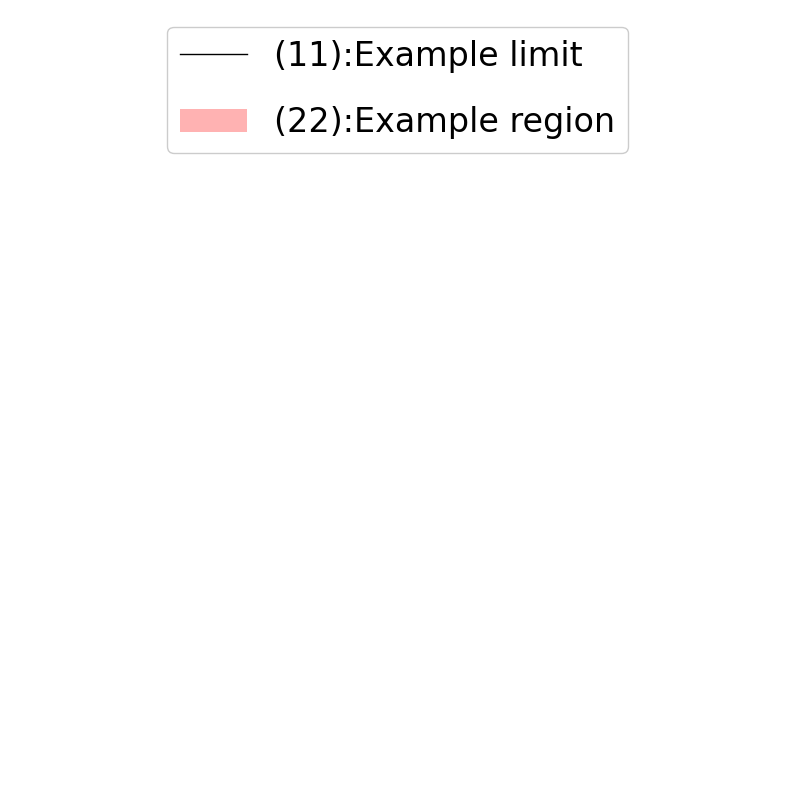

In [5]:
legend_fig = await render_legend_core(
    display_data_list=display_data_list,
    output_type="notebook",
)

display(legend_fig)

In [10]:
## You need to enter your email address into the colab secrets
## see key in left hand bar
## The library cleans the email address provided
## First time you run this you need to give permission to the notebook to access each of the secrets
from google.colab import userdata
email = userdata.get('DM_TOOLS_EMAIL')
api_key = userdata.get('DM_TOOLS')
# print(email)

Create the API Client - this connects to the server and allows simpler interactions.

For less verbose calling, you can set suppress_logs=True

In [11]:
Client = APIClient(email, api_key, suppress_logs=False)

Query using key pair - full match on word
Requirement was to exact word match for the key value pair

Example match to CDMS but not to CDMSSuper

Below returns a list and the results need to be loaded as json

In [35]:
r_id = Client.read(id=19173)
properties_json = r_id[0]['properties']
properties_json

2026-11-06 11:58:25,294 - dmtools_libraries.client - INFO - Calling read data API
INFO:dmtools_libraries.client:Calling read data API
/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'app.dmtools.brown.edu'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


{'comment': 'LZ 2025 limit',
 'dateAnnouncement': '2025-07-01',
 'dateEnd': None,
 'dateOfficial': None,
 'dateStart': None,
 'defaultColor': 'blue',
 'defaultStyle': 'line',
 'experiment': 'LUX-ZEPLIN',
 'greatestHit': 0,
 'label': 'LZ 01 Jul 2025 WS2024 Limit',
 'label_short': 'LZ 1 Jul 2024 Limit',
 'measurementType': 'Dir',
 'official': 1,
 'open': 0,
 'public': 0,
 'rating': 80,
 'raw': '{[9 9.80e-47;\n11 2.64e-47;\n13 1.21e-47;\n16 5.86e-48;\n17 5.05e-48;\n19 3.92e-48;\n21 3.26e-48;\n23 2.91e-48;\n26 2.58e-48;\n29 2.43e-48;\n32 2.29e-48;\n36 2.21e-48;\n40 2.18e-48;\n43 2.22e-48;\n46 2.27e-48;\n65 2.55e-48;\n91 3.21e-48;\n129 4.21e-48;\n182 5.53e-48;\n256 8.15e-48;\n361 1.10e-47;\n508 1.55e-47;\n1008 3.06e-47;\n2000 5.73e-47;\n5000 1.44e-46;\n10000 2.93e-46]}',
 'reference': 'LZ Spokesperson richard_gaitskell@brown.edu. https://arxiv.org/pdf/2410.17036',
 'resultType': 'Exp',
 'spinDependency': 'SI',
 'values': [[[9.0, 9.8e-47],
   [11.0, 2.64e-47],
   [13.0, 1.21e-47],
   [16.0, 

In [32]:
display_data_list = [
    {
        "record": {"id": 1},
        "properties": {"color": "blue", "style": "line"},
        "data": [{
            "record": {"id": 11},
            "properties": properties_json
        }]
    }
]

In [36]:
plot_data = {
    "plot_node": {
        "record": {"id": 101}
    }
}

plot_properties = {
    "name": "Colab render test",
    "plotType": "Cross Section vs WIMP Mass",
    "xUnits": "GeV/c^2",
    "xMin": 0.1,
    "xMax": 1000,
    "yMin": -48,  # y-axis bounds are powers of 10
    "yMax": -46,
}

Colab render test


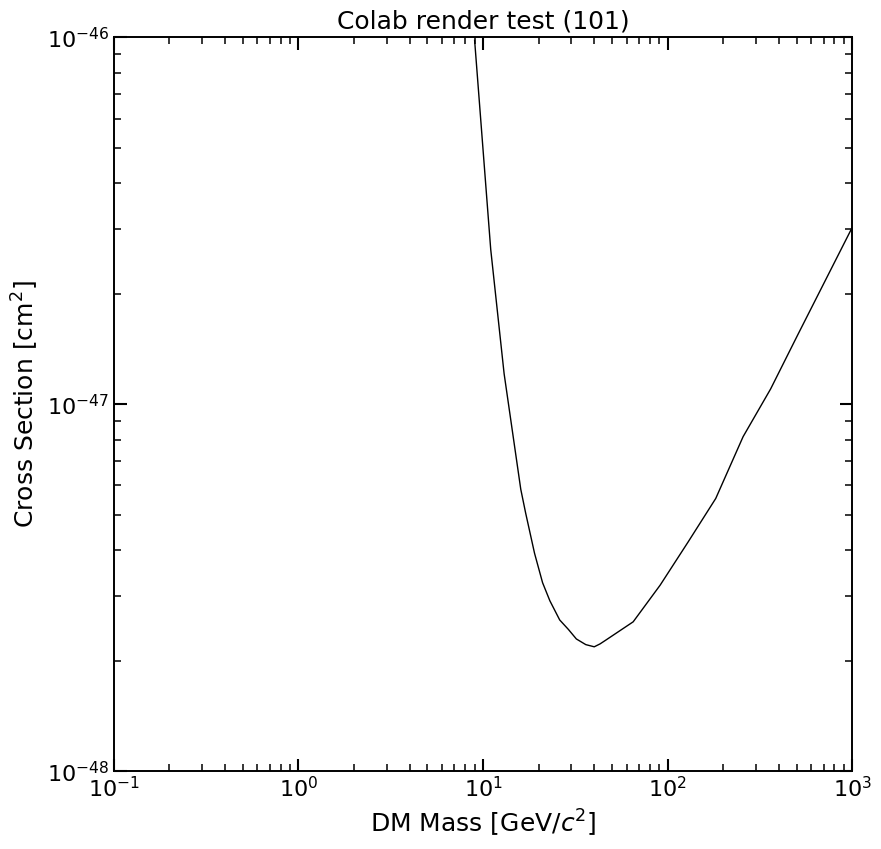

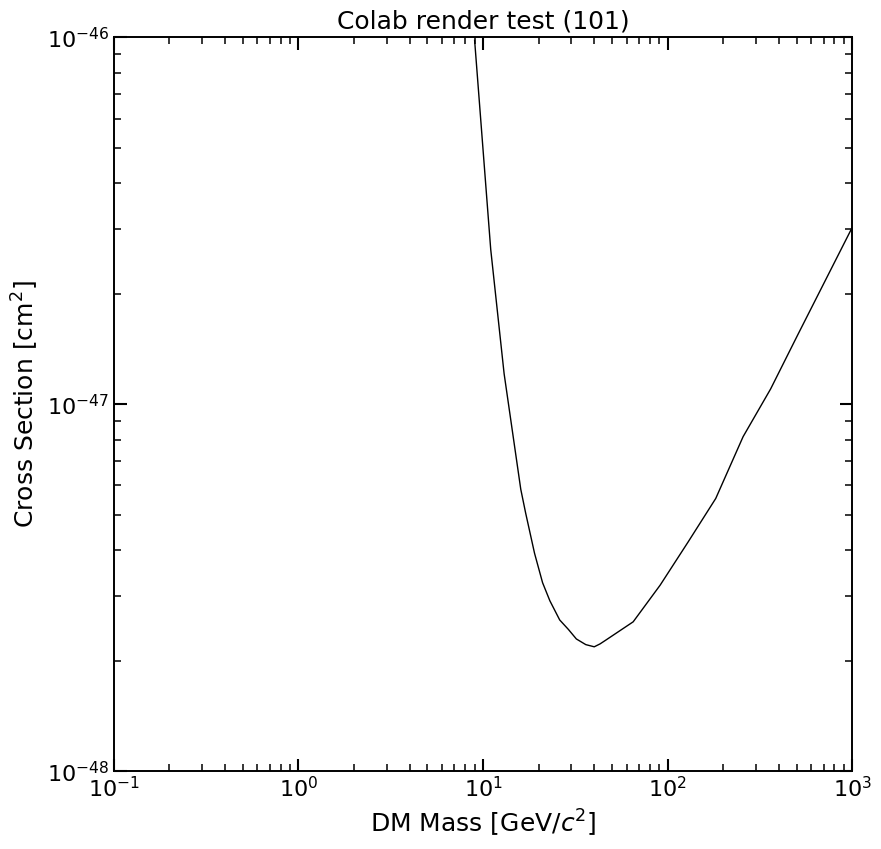

In [37]:
# @title Default title text
plot_name, plot_fig = await render_plot_core(
    plot_data=plot_data,
    plot_properties=plot_properties,
    display_data_list=display_data_list,
    output_format="object",
)

print(plot_name)
display(plot_fig)